# 05 – Comparison and feature analysis (corrected)

Replaces the comparison and feature analysis in `04_feature_analysis_comparison.ipynb` and the hard-coded chart in `elm_experiment.ipynb`.

**What changed**
1. **Rows are aligned.** The original matched autoencoder flags to feature rows by position (`iloc[:min_len]`) from files with different row orders, so the feature-importance chart compared unrelated rows. Here every score is joined on the same `row_id`.
2. **No hard-coded numbers.** The comparison chart is built from the saved results of notebooks 03 and 04.
3. **A capture-confound check** is added: how well the autoencoder separates normal traffic from the two different captures. A high score there means part of the "attack detection" may be the model telling the two network environments apart.

In [1]:
import os, random, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
from sklearn.metrics import roc_auc_score

In [2]:
ae = pd.read_csv("results/ae_test_scores.csv")
ie = pd.read_csv("results/if_elm_test_scores.csv")
scores = ae.merge(ie, on=["row_id", "label"], validate="one_to_one")
assert len(scores) == len(ae) == len(ie), "Row alignment failed"

ae_t = pd.read_csv("results/ae_thresholds.csv")
if_t = pd.read_csv("results/if_thresholds.csv")
ae_s = json.load(open("results/ae_summary.json"))
ie_s = json.load(open("results/if_elm_summary.json"))

summary = pd.concat([ae_t.drop(columns="threshold"), if_t, pd.DataFrame([ie_s["elm"]]).drop(columns="roc_auc")], ignore_index=True)
auc = pd.DataFrame([{"model": "Autoencoder", "roc_auc": ae_s["roc_auc"], "pr_auc": ae_s["pr_auc"]},
                    {"model": "Isolation Forest (all traffic)", "roc_auc": ie_s["if_roc_auc"], "pr_auc": ie_s["if_pr_auc"]},
                    {"model": "Isolation Forest (normal-only)", "roc_auc": ie_s["ifn_roc_auc"], "pr_auc": ie_s["ifn_pr_auc"]},
                    {"model": "ELM (supervised)", "roc_auc": ie_s["elm"]["roc_auc"], "pr_auc": np.nan}])
summary.to_csv("results/final_comparison.csv", index=False)
display(auc.round(4))
summary.round(3)

,model,roc_auc,pr_auc
0,Autoencoder,0.9827,0.9968
1,Isolation Forest (all traffic),0.1431,0.7269
2,Isolation Forest (normal-only),0.7669,0.9264
3,ELM (supervised),0.9963,NaN


,model,precision,recall,f1,false_positive_rate
0,Autoencoder (95th pct),0.990,0.885,0.935,0.053
1,Autoencoder (90th pct),0.981,0.979,0.980,0.110
2,Autoencoder (85th pct),0.973,0.983,0.978,0.155
3,Autoencoder (80th pct),0.965,0.983,0.974,0.203
4,Isolation Forest (contamination=0.05),0.513,0.033,0.062,0.179
5,Isolation Forest (95th pct),0.355,0.005,0.010,0.052
6,Isolation Forest (90th pct),0.411,0.013,0.025,0.107
7,Isolation Forest (85th pct),0.568,0.032,0.061,0.141
8,Isolation Forest (80th pct),0.523,0.038,0.071,0.199
9,"Isolation Forest, normal-only (95th pct)",0.938,0.151,0.260,0.057


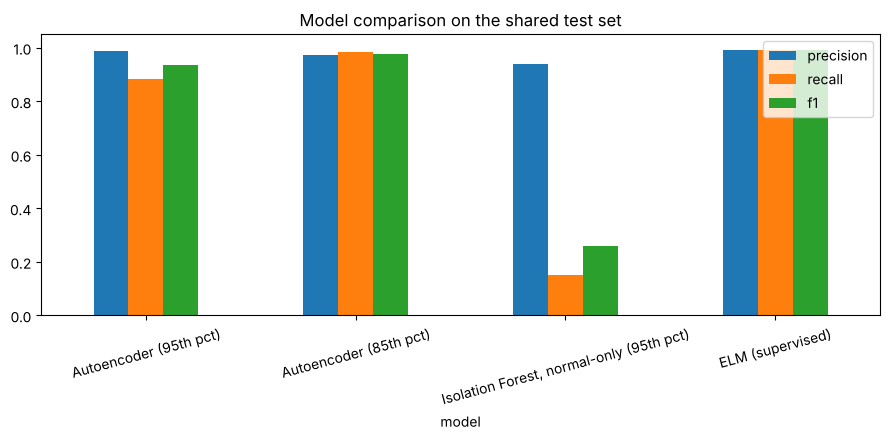

In [3]:
pick = summary[summary["model"].isin(["Autoencoder (95th pct)", "Autoencoder (85th pct)",
                                       "Isolation Forest, normal-only (95th pct)", "ELM (supervised)"])].set_index("model")
pick[["precision", "recall", "f1"]].plot(kind="bar", figsize=(9, 4.5), ylim=(0, 1.05),
                                          title="Model comparison on the shared test set")
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig("figures/model_comparison.png", dpi=150); plt.show()

## Agreement between Autoencoder and Isolation Forest (normal-only), 95th percentile thresholds

In [4]:
ae_flag = scores["ae_error"] > ae_s["val_err_percentiles"]["95"]
if_flag = scores["ifn_score"] > ie_s["ifn_val_percentiles"]["95"]
print(f"Agreement: {(ae_flag == if_flag).mean():.2%}")
print(pd.crosstab(ae_flag.rename("AE flags"), if_flag.rename("IF flags")))

Agreement: 36.08%
IF flags  False  True 
AE flags              
False      6037    190
True      16520   3396


## Feature analysis on aligned rows

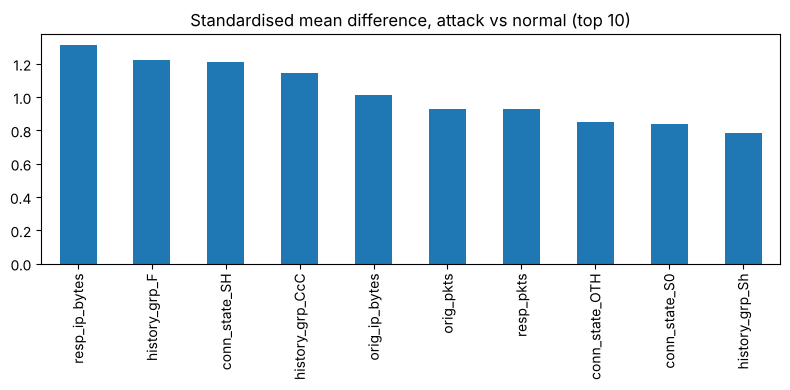

,std_mean_difference,ae_extra_error
resp_ip_bytes,1.311,0.349
history_grp_F,1.224,1.161
conn_state_SH,1.209,3.060
history_grp_CcC,1.146,2.897
orig_ip_bytes,1.010,2.859
orig_pkts,0.930,3.287
resp_pkts,0.926,2.317
conn_state_OTH,0.850,1.091
conn_state_S0,0.840,3.768
history_grp_Sh,0.782,2.777


In [5]:
feat = pd.read_csv("features_conn.csv")
cap = feat["capture"]
F = feat.drop(columns=["label", "capture", "split"]).iloc[scores["row_id"].values].reset_index(drop=True)
std = F.std().replace(0, 1)
diff = ((F[scores["label"] == 1].mean() - F[scores["label"] == 0].mean()) / std).abs().sort_values(ascending=False)
diff.head(10).plot(kind="bar", figsize=(8, 4), title="Standardised mean difference, attack vs normal (top 10)")
plt.tight_layout(); plt.savefig("figures/feature_difference.png", dpi=150); plt.show()

contrib = pd.read_csv("results/ae_feature_contribution.csv", index_col=0)["extra_error"]
pd.DataFrame({"std_mean_difference": diff.head(10).round(3),
              "ae_extra_error": contrib.reindex(diff.head(10).index).round(3)})

## Capture-confound check
Normal traffic comes from two captures recorded three weeks apart. If the autoencoder scores normal traffic from the DDoS-day capture much higher than normal traffic from the normal-day capture, environment differences are contributing to the scores.

In [6]:
normal_rows = scores[scores["label"] == 0].copy()
normal_rows["capture"] = cap.iloc[normal_rows["row_id"].values].values
print(normal_rows.groupby("capture")["ae_error"].describe()[["count", "50%", "mean"]])
is_ddos_day = (normal_rows["capture"] == "normal_DDoS_1").astype(int)
print(f"\nAUC for telling the two normal captures apart from AE error: {roc_auc_score(is_ddos_day, normal_rows['ae_error']):.3f}")
print("(0.5 = no difference between captures; close to 1.0 = strong environment effect)")

                count       50%      mean
capture                                  
normal_2       1431.0  0.000277  0.014327
normal_DDoS_1  2450.0  0.000637  0.008153

AUC for telling the two normal captures apart from AE error: 0.441
(0.5 = no difference between captures; close to 1.0 = strong environment effect)


# Results summary

See `README_corrections.md` in this folder for the full list of corrections, the results table and the comparison with the submitted thesis.

## Comparison with the submitted thesis

- **The main conclusion holds, and is stronger.** An autoencoder trained only on normal traffic detects DDoS connections well: ROC-AUC 0.98, against roughly 0.91–0.94 originally.
- **The threshold trade-off holds but is gradual.** Moving from the 95th to the 90th percentile raises recall from 0.89 to 0.98 and doubles the false-positive rate from 5% to 11%. The sharp jump in the thesis (recall 0.39 → ~1.0) does not appear once labels and features are corrected.
- **The Isolation Forest results in the thesis (precision 0.94, recall 0.91) cannot be reproduced.** Isolation Forest assumes anomalies are rare. Here 88% of the training traffic is attack traffic, so the forest treats attacks as normal (ROC-AUC 0.14). Trained on normal traffic only, it reaches ROC-AUC 0.77 but recall of only 15–36%.
- **Autoencoder–Isolation Forest agreement is 36%, not 94%.**
- **ELM (0.99) is consistent with the thesis.** It is supervised, so it is not a like-for-like comparison with the unsupervised models.
- **Both kinds of feature matter.** Attacks differ from normal traffic in volume features (bytes, packets) and in connection-state flags (`SH`, `S0`, history `F`). This reconciles the thesis text, which named volume features, with its own figure, which showed connection-state flags.
- **Capture-confound check: AUC 0.44.** The autoencoder does not score normal traffic from the two capture days differently, so it is not simply telling the two network environments apart.

